# Bagging

**B**ootstrap **agg**regat**ing**. Train many models, each on a different random resample of the training set (drawn *with replacement*, so ~63% of the distinct rows appear), then combine by majority vote.

Why it works: a deep decision tree has low bias but **high variance** — change the data slightly and the tree changes a lot. Averaging many such trees cancels the noise while keeping the low bias. Models that are already stable (e.g. linear regression) gain little.

- Works with **any base learner**: pass `make_estimator=lambda: MyModel()`. The default is a CART tree.
- **Out-of-bag score:** each model never saw the ~37% of rows left out of its bootstrap sample, so predicting those rows with only the models that didn't train on them gives a free validation estimate (`oob_score_`) — no hold-out set needed.
- Trees are trained independently, so this parallelizes trivially.

Next steps from here: `19_random_forest` also samples *features* at each split to decorrelate the trees; `20_extra_trees` randomizes the split thresholds too.

## Usage

```python
# (the class is defined in the Implementation section below)

model = BaggingClassifier(n_estimators=50).fit(X_train, y_train)
preds = model.predict(X_test)
print(model.oob_score_)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class _Tree:
    """Plain CART classifier (Gini, all features). The default base learner for Bagging."""

    def __init__(self, max_depth=None, min_samples_split=2, n_classes=2):
        self.max_depth = max_depth if max_depth is not None else 10**9
        self.min_samples_split = min_samples_split
        self.n_classes = n_classes

    def fit(self, X, y):
        self.root = self._grow(X, np.eye(self.n_classes)[y], 0)
        return self

    def predict(self, X):
        return np.array([self._traverse(x, self.root) for x in X])

    def _grow(self, X, Y, depth):
        counts = Y.sum(axis=0)
        n = len(Y)
        if depth >= self.max_depth or n < self.min_samples_split or counts.max() == n:
            return counts.argmax()

        best_score, best_feature, best_threshold = (counts**2).sum() / n + 1e-12, None, None
        for f in range(X.shape[1]):
            order = np.argsort(X[:, f])
            xs = X[order, f]
            left = np.cumsum(Y[order], axis=0)[:-1]
            n_left = np.arange(1, n)[:, None]
            right = counts - left
            # maximizing sum(c^2/n) over both sides == minimizing the weighted Gini impurity
            score = (left**2 / n_left).sum(axis=1) + (right**2 / (n - n_left)).sum(axis=1)
            score = np.where(xs[1:] != xs[:-1], score, -np.inf)
            i = score.argmax()
            if score[i] > best_score:
                best_score, best_feature, best_threshold = score[i], f, (xs[i] + xs[i + 1]) / 2

        if best_feature is None:
            return counts.argmax()
        mask = X[:, best_feature] <= best_threshold
        return (best_feature, best_threshold,
                self._grow(X[mask], Y[mask], depth + 1), self._grow(X[~mask], Y[~mask], depth + 1))

    def _traverse(self, x, node):
        while isinstance(node, tuple):
            feature, threshold, left, right = node
            node = left if x[feature] <= threshold else right
        return node


class BaggingClassifier:
    """Bootstrap AGGregatING: train each model on a random resample (with replacement) of the
    data, then majority-vote. Averaging many high-variance models cuts the variance while the
    bias stays the same -- which is why it helps unstable learners like deep trees.

    make_estimator: zero-argument function returning a NEW unfitted model with fit(X, y) and
    predict(X). Default is a CART tree, but any learner works (e.g. lambda: KNN(k=3)).
    Labels passed to the base models are integers 0..k-1.

    After fitting, oob_score_ is accuracy measured on the samples each model did NOT see:
    a free validation estimate, no hold-out set needed."""

    def __init__(self, make_estimator=None, n_estimators=25, max_samples=1.0, max_depth=None,
                 random_state=0):
        self.make_estimator = make_estimator
        self.n_estimators = n_estimators
        self.max_samples = max_samples
        self.max_depth = max_depth
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        n, k = len(X), len(self.classes_)
        make = self.make_estimator or (lambda: _Tree(self.max_depth, n_classes=k))

        rng = np.random.default_rng(self.random_state)
        size = max(1, int(self.max_samples * n))
        self.estimators_ = []
        oob_votes = np.zeros((n, k))
        for _ in range(self.n_estimators):
            idx = rng.integers(0, n, size)  # bootstrap sample
            model = make().fit(X[idx], y_enc[idx])
            self.estimators_.append(model)
            out_of_bag = np.setdiff1d(np.arange(n), idx)
            if len(out_of_bag):
                oob_votes[out_of_bag, model.predict(X[out_of_bag])] += 1

        seen = oob_votes.sum(axis=1) > 0  # a sample that was in every bootstrap has no OOB vote
        self.oob_score_ = (oob_votes[seen].argmax(axis=1) == y_enc[seen]).mean()
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        votes = np.array([m.predict(X) for m in self.estimators_])  # (n_estimators, n_samples)
        k = len(self.classes_)
        winners = [np.bincount(col, minlength=k).argmax() for col in votes.T]
        return self.classes_[winners]

## See it work

### 1. Averaging many unstable trees gives a smooth, stable boundary

A single fully-grown tree memorises the noisy training points (jagged boundary, high variance). Bagging trains each tree on a **bootstrap resample** (sample with replacement) and takes a majority vote. Each tree is wrong in a different way, and the votes cancel.

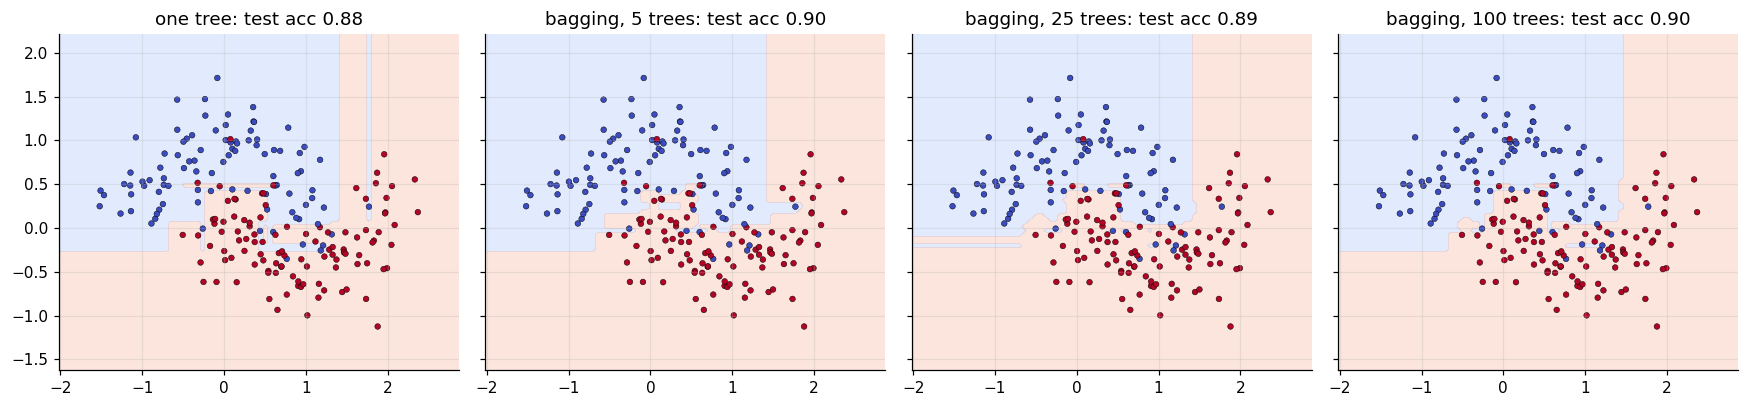

In [3]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

Xm, ym = make_moons(n_samples=400, noise=0.3, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.5, random_state=0)
acc = lambda m, X, y: (m.predict(X) == y).mean()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
single = _Tree(n_classes=2).fit(Xtr, ytr)
plot_boundary(axes[0], single, Xtr, ytr, n=90); axes[0].set_title(f"one tree: test acc {acc(single, Xte, yte):.2f}")
for ax, n in zip(axes[1:], [5, 25, 100]):
    bag = BaggingClassifier(n_estimators=n).fit(Xtr, ytr)
    plot_boundary(ax, bag, Xtr, ytr, n=90); ax.set_title(f"bagging, {n} trees: test acc {acc(bag, Xte, yte):.2f}")
plt.tight_layout(); plt.show()

### 2. More trees help, with diminishing returns, and the OOB score is a free validation

Test accuracy improves quickly then flattens (bagging cannot overfit by adding trees, it just stops improving). Each tree never sees about 37% of the samples, so predicting those with the trees that missed them gives an **out-of-bag score** that tracks test accuracy without needing a hold-out set.

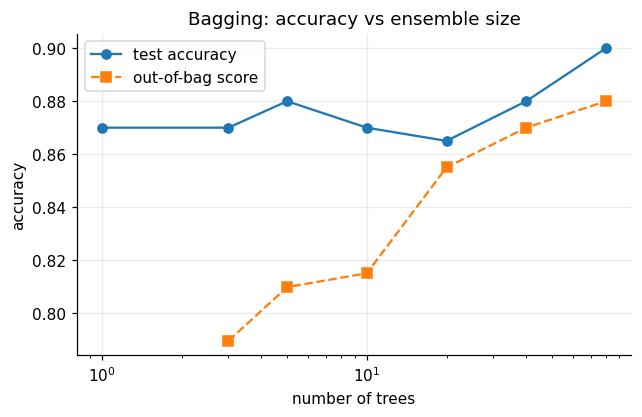

In [4]:
ns = [1, 3, 5, 10, 20, 40, 80]
res = [BaggingClassifier(n_estimators=n, random_state=1).fit(Xtr, ytr) for n in ns]
plt.figure(figsize=(6.5, 3.8))
plt.plot(ns, [acc(m, Xte, yte) for m in res], "o-", label="test accuracy")
plt.plot(ns[1:], [m.oob_score_ for m in res[1:]], "s--", label="out-of-bag score")
plt.xscale("log"); plt.xlabel("number of trees"); plt.ylabel("accuracy"); plt.legend(); plt.title("Bagging: accuracy vs ensemble size"); plt.show()

### 3. Why 37%? The bootstrap

Drawing `n` samples with replacement from `n` leaves each sample out with probability `(1 − 1/n)ⁿ → 1/e ≈ 0.368`. So a bootstrap contains about **63.2%** of the distinct points; the rest are the out-of-bag set.

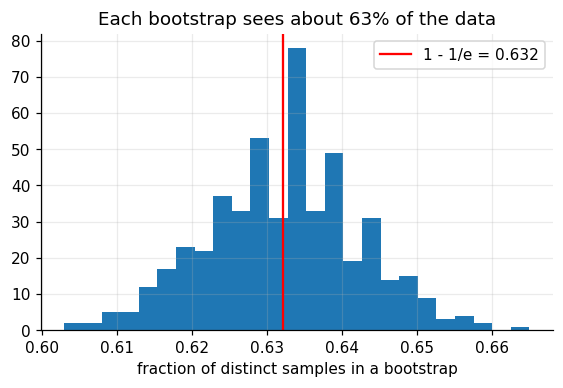

In [5]:
rng = np.random.default_rng(0)
n = 1000
frac = [len(np.unique(rng.integers(0, n, n))) / n for _ in range(500)]
plt.figure(figsize=(6, 3.5)); plt.hist(frac, bins=25); plt.axvline(1 - 1 / np.e, color="r", label="1 - 1/e = 0.632")
plt.xlabel("fraction of distinct samples in a bootstrap"); plt.legend(); plt.title("Each bootstrap sees about 63% of the data"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import BaggingClassifier as SklearnBagging
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

ours = BaggingClassifier(n_estimators=50).fit(X_train, y_train)
theirs = SklearnBagging(DecisionTreeClassifier(), n_estimators=50, oob_score=True, random_state=0).fit(X_train, y_train)
single = _Tree(n_classes=2).fit(X_train, y_train)

acc = lambda pred: (pred == y_test).mean()
print("breast cancer test accuracy: ours=%.4f sklearn=%.4f  (one tree alone: %.4f)"
      % (acc(ours.predict(X_test)), acc(theirs.predict(X_test)), acc(single.predict(X_test))))
print("out-of-bag score:            ours=%.4f sklearn=%.4f" % (ours.oob_score_, theirs.oob_score_))
assert abs(acc(ours.predict(X_test)) - acc(theirs.predict(X_test))) < 0.04
assert abs(ours.oob_score_ - theirs.oob_score_) < 0.03

breast cancer test accuracy: ours=0.9649 sklearn=0.9532  (one tree alone: 0.9240)
out-of-bag score:            ours=0.9447 sklearn=0.9523


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _noisy_data(seed, n=400, flip=0.15):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 2))
    y = (X[:, 0] + X[:, 1] > 0).astype(int)
    noisy = rng.random(n) < flip
    return X, np.where(noisy, 1 - y, y), (X[:, 0] + X[:, 1] > 0).astype(int)  # last = true labels


def test_tree_learns_a_simple_split():
    X = np.array([[1.0], [2.0], [3.0], [8.0], [9.0], [10.0]])
    y = np.array([0, 0, 0, 1, 1, 1])
    assert (_Tree(n_classes=2).fit(X, y).predict(X) == y).all()


def test_bagging_beats_one_overfit_tree_on_noisy_labels():
    X, y, _ = _noisy_data(0)
    X_test, _, y_test_true = _noisy_data(1, n=1000)
    single = _Tree(n_classes=2).fit(X, y)  # unlimited depth: memorizes the label noise
    bag = BaggingClassifier(n_estimators=40).fit(X, y)
    acc = lambda m: (m.predict(X_test) == y_test_true).mean()
    assert acc(bag) > acc(single) + 0.02


def test_oob_score_estimates_generalization_without_a_holdout():
    X, y, _ = _noisy_data(2)
    X_test, y_test, _ = _noisy_data(3, n=2000)
    model = BaggingClassifier(n_estimators=60).fit(X, y)
    assert abs(model.oob_score_ - (model.predict(X_test) == y_test).mean()) < 0.06


def test_any_base_learner_and_string_labels():
    class Centroid:  # tiny base learner: nearest class mean
        def fit(self, X, y):
            self.m = np.array([X[y == c].mean(axis=0) for c in np.unique(y)])
            self.c = np.unique(y)
            return self

        def predict(self, X):
            return self.c[np.argmin(((X[:, None] - self.m[None]) ** 2).sum(-1), axis=1)]

    rng = np.random.default_rng(0)
    X = np.vstack([rng.normal(-3, 1, (50, 2)), rng.normal(3, 1, (50, 2))])
    y = np.array(["no"] * 50 + ["yes"] * 50)
    model = BaggingClassifier(make_estimator=Centroid, n_estimators=10).fit(X, y)
    assert (model.predict(X) == y).mean() > 0.97

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_tree_learns_a_simple_split
PASS test_bagging_beats_one_overfit_tree_on_noisy_labels


PASS test_oob_score_estimates_generalization_without_a_holdout
PASS test_any_base_learner_and_string_labels

all 4 tests passed


## Takeaways

- **Use it** to reduce the **variance** of a high-variance base learner (deep trees, kNN with small `k`). It does not reduce bias, so weak biased learners (stumps) do not improve much.
- **Recipe:** bootstrap sample, fit a model, repeat `T` times; vote (classification) or average (regression). Trees can be trained in parallel.
- **Random Forest** (`19_random_forest`) is bagging plus random feature subsets, which decorrelates the trees even further.
- **Interview line:** *"Bagging = bootstrap + average: variance drops roughly by `1/T` for uncorrelated models; OOB samples give a free validation score."*